In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

In [2]:
# --- 1. Configuration ---
REAL_DATA_PATH = '../../../data/data_with_features.csv'
SYNTHETIC_DATA_PATH = '../../../data/syntheticData/synthetic_data_sarima_statsmodels.csv'
TARGET_COLUMN = 'cumulative_mite_count'
GROUP_COLUMN = 'treatment_id'

# Define the chronological split for your REAL data
TRAIN_RATIO = 0.8
VALIDATION_RATIO = 0.1
# The rest will be the TEST_RATIO (1.0 - 0.8 - 0.1 = 0.1)

In [4]:
# --- 2. Feature Engineering Function ---
print("--- 🛠️  Defining Feature Engineering Function ---")
def create_features(df):
    """Creates time-series features from a dataframe in a group-aware manner."""
    df = df.copy()
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df = df.sort_values(by=[GROUP_COLUMN, 'observation_date'])

    # Time-based features
    df['dayofweek'] = df['observation_date'].dt.dayofweek
    df['month'] = df['observation_date'].dt.month
    df['weekofyear'] = df['observation_date'].dt.isocalendar().week.astype(int)
    
    # Lag features (shifted within each group)
    df['lag_1'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(1)
    df['lag_3'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(3)
    df['lag_7'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(7)
    
    # Rolling window features
    df['rolling_mean_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).mean().reset_index(drop=True)
    df['rolling_std_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).std().reset_index(drop=True)
    
    # Drop the initial rows with NaNs created by the largest lag
    df = df.dropna()
    return df

--- 🛠️  Defining Feature Engineering Function ---


In [5]:
# --- 3. Process Real and Synthetic Data ---
print("\n--- 🔄 Processing Datasets ---")
# Load and process REAL data
real_df = pd.read_csv(REAL_DATA_PATH)
real_featured_df = create_features(real_df)
print(f"   Real data features created. Shape after dropping NaNs: {real_featured_df.shape}")

# Load and process SYNTHETIC data
synthetic_df = pd.read_csv(SYNTHETIC_DATA_PATH)
# Create unique IDs for synthetic data BEFORE feature engineering
synthetic_df[GROUP_COLUMN] = synthetic_df[GROUP_COLUMN].astype(str) + '_synth'
synthetic_featured_df = create_features(synthetic_df)
print(f"   Synthetic data features created. Shape after dropping NaNs: {synthetic_featured_df.shape}")


--- 🔄 Processing Datasets ---
   Real data features created. Shape after dropping NaNs: (2083, 22)
   Synthetic data features created. Shape after dropping NaNs: (2189, 22)


In [6]:
# --- 4. Chronological Split (on feature-engineered REAL data) ---
print("\n--- 🔪 Splitting Real Data into Train, Validation, and Test Sets ---")
train_real_list, val_real_list, test_real_list = [], [], []

for group_id, group_df in real_featured_df.groupby(GROUP_COLUMN):
    n_rows = len(group_df)
    train_end = int(n_rows * TRAIN_RATIO)
    val_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))
    
    train_real_list.append(group_df.iloc[:train_end])
    val_real_list.append(group_df.iloc[train_end:val_end])
    test_real_list.append(group_df.iloc[val_end:])

train_real_df = pd.concat(train_real_list)
val_df = pd.concat(val_real_list)
test_df = pd.concat(test_real_list)


--- 🔪 Splitting Real Data into Train, Validation, and Test Sets ---


In [7]:
# --- 5. Create Augmented Training Set ---
print("\n--- ➕ Creating Augmented Training Set (Real + Synthetic) ---")
train_ids = train_real_df[GROUP_COLUMN].unique()
# The synthetic group IDs already have the '_synth' suffix
synthetic_train_ids = [str(tid) + '_synth' for tid in train_ids]
synthetic_train_df = synthetic_featured_df[synthetic_featured_df[GROUP_COLUMN].isin(synthetic_train_ids)]

augmented_df = pd.concat([train_real_df, synthetic_train_df], ignore_index=True)
print(f"   Augmented Training Set Shape: {augmented_df.shape}")


--- ➕ Creating Augmented Training Set (Real + Synthetic) ---
   Augmented Training Set Shape: (3750, 22)


In [8]:
# --- 6. Final Preparation for Modeling ---
print("\n--- ✅ Finalizing Data for Feature-Based Models ---")
features_to_use = [
    'dayofweek', 'month', 'weekofyear', 'lag_1', 'lag_3', 'lag_7',
    'rolling_mean_7', 'rolling_std_7', 'initial_female_count', 'leaf_area_cm2',
    'population_density', 'initial_growth_potential'
]

X_train = augmented_df[features_to_use]
y_train = augmented_df[TARGET_COLUMN]

X_val = val_df[features_to_use]
y_val = val_df[TARGET_COLUMN]

X_test = test_df[features_to_use]
y_test = test_df[TARGET_COLUMN]

# Scale the feature data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"\n   Data is now ready for training.")
print(f"   X_train shape: {X_train_scaled.shape}, y_train shape: {y_train.shape}")
print(f"   X_val shape:   {X_val_scaled.shape}, y_val shape: {y_val.shape}")
print(f"   X_test shape:  {X_test_scaled.shape}, y_test shape: {y_test.shape}")


--- ✅ Finalizing Data for Feature-Based Models ---

   Data is now ready for training.
   X_train shape: (3750, 12), y_train shape: (3750,)
   X_val shape:   (202, 12), y_val shape: (202,)
   X_test shape:  (305, 12), y_test shape: (305,)


In [24]:
X_train

,dayofweek,month,weekofyear,lag_1,lag_3,lag_7,rolling_mean_7,rolling_std_7,initial_female_count,leaf_area_cm2,population_density,initial_growth_potential
0,3,8,32,16.0,9.0,0.0,6.571429,6.373307,1,0.5,2.000000,0.5
1,4,8,32,18.0,13.0,0.0,9.142857,6.890297,1,0.5,2.000000,0.5
2,6,8,32,21.0,16.0,2.0,12.142857,6.817345,1,0.5,2.000000,0.5
3,0,8,33,28.0,18.0,6.0,15.857143,7.425824,1,0.5,2.000000,0.5
4,1,8,33,37.0,21.0,9.0,20.285714,9.516902,1,0.5,2.000000,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...
3745,5,12,50,529.0,504.0,385.0,472.428571,54.588940,4,15.0,0.266667,60.0
3746,6,12,50,538.0,525.0,419.0,494.285714,43.188402,3,15.0,0.200000,45.0
3747,0,12,51,549.0,529.0,458.0,512.857143,31.892677,3,15.0,0.200000,45.0
3748,1,12,51,557.0,538.0,487.0,527.000000,24.637370,3,15.0,0.200000,45.0


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_error
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", category=UserWarning) # Suppress XGBoost warnings if they pop up

# --- 1. Train the Baseline Model ---
print("--- 🏋️ Phase 2: Training Baseline Model (Linear Regression) ---")

# Initialize and train the model on the scaled training data
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# --- 2. Evaluate One-Step-Ahead Performance on Validation Set ---
print("\n--- 📊 Evaluating single-day prediction performance on VALIDATION set ---")

# Predict the next day's count given the true history
val_predictions = lr_model.predict(X_val_scaled)

# Calculate metrics for these single-step predictions
rmse_val_onestep = np.sqrt(mean_squared_error(y_val, val_predictions))
mae_val_onestep = mean_absolute_error(y_val, val_predictions)
r2_val_onestep = r2_score(y_val, val_predictions)
mse_val_onestep = mean_squared_error(y_val, val_predictions)


print(f"   One-Step Validation MAE:  {mae_val_onestep:.4f}")
print(f"   One-Step Validation MSE:   {mse_val_onestep:.4f}")
print(f"   One-Step Validation RMSE: {rmse_val_onestep:.4f}")
print(f"   One-Step Validation R²:   {r2_val_onestep:.4f}")
print("   (This shows how well the model predicts just the next day given perfect history)")


# --- 3. Define the 15-Day Autoregressive Forecasting Function ---
print("\n--- 🔄 Defining the 15-day Forecasting Loop ---")

def forecast_trajectory(model, initial_features, num_days_to_forecast, scaler, group_cols):
    """
    Generates a multi-step forecast using an autoregressive loop.
    
    Args:
        model: The trained forecasting model.
        initial_features (pd.DataFrame): A single row of features representing the last known day.
        num_days_to_forecast (int): The number of steps to predict (e.g., 15).
        scaler: The fitted scikit-learn scaler.
        group_cols (list): Columns that identify the group (e.g., ['treatment_id']).
        
    Returns:
        np.array: An array of the forecasted values.
    """
    forecast = []
    
    # Use the last known features as the starting point for the loop
    current_features = initial_features.copy()

    for _ in range(num_days_to_forecast):
        # Scale the current features
        current_features_scaled = scaler.transform(current_features)
        
        # Predict the next step
        next_prediction = model.predict(current_features_scaled)[0]
        
        # Ensure prediction is non-negative
        next_prediction = max(0, next_prediction)
        forecast.append(next_prediction)
        
        # --- Update features for the NEXT iteration ---
        # This is the 'autoregressive' part
        
        # Shift lags: lag_7 becomes the old lag_3, lag_3 becomes old lag_1, etc.
        current_features['lag_7'] = current_features['lag_3']
        current_features['lag_3'] = current_features['lag_1']
        current_features['lag_1'] = next_prediction # The new prediction becomes the most recent lag
        
        # Update rolling features (simplified for forecasting loop)
        # In a real scenario, this would involve keeping a history of recent predictions
        current_features['rolling_mean_7'] = (current_features['rolling_mean_7'] * 6 + next_prediction) / 7
        
        # Note: Updating time-based features (dayofweek, etc.) would require a more complex setup
        # For this experiment, we'll assume their impact is secondary to the lag features.

    return np.array(forecast)

print("   Forecasting function is ready.")

--- 🏋️ Phase 2: Training Baseline Model (Linear Regression) ---

--- 📊 Evaluating single-day prediction performance on VALIDATION set ---
   One-Step Validation MAE:  2.3709
   One-Step Validation MSE:   11.0667
   One-Step Validation RMSE: 3.3267
   One-Step Validation R²:   0.9996
   (This shows how well the model predicts just the next day given perfect history)

--- 🔄 Defining the 15-day Forecasting Loop ---
   Forecasting function is ready.


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# This script assumes all data variables (X_train_scaled, y_train, val_featured, y_val etc.)
# from the Phase 1: Data Preparation script are in memory.

# --- 1. Train the Baseline Model ---
print("--- 🏋️ Tier 1: Training Baseline Model (Linear Regression) ---")
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
print("   ✅ Linear Regression model trained.")


# --- 2. Define Forecasting and Evaluation Functions ---
print("\n--- 🔄 Defining Forecasting and Evaluation Logic ---")

def forecast_trajectory(model, initial_features_df, num_days_to_forecast, scaler, feature_columns):
    """Generates a multi-step forecast using an autoregressive loop."""
    forecast = []
    current_features = initial_features_df[feature_columns].copy()
    for _ in range(num_days_to_forecast):
        current_features_scaled = scaler.transform(current_features)
        next_prediction = model.predict(current_features_scaled)[0]
        next_prediction = max(0, next_prediction)
        forecast.append(next_prediction)
        
        # Update features for the next iteration (autoregression)
        current_features['lag_7'] = current_features['lag_3']
        current_features['lag_3'] = current_features['lag_1']
        current_features['lag_1'] = next_prediction
        current_features['rolling_mean_7'] = (current_features['rolling_mean_7'] * 6 + next_prediction) / 7
    return np.array(forecast)

def evaluate_trajectory_performance(model, eval_df, scaler, feature_columns):
    """Evaluates a model's full multi-step trajectory performance."""
    all_predictions, all_true_values = [], []
    for group_id in eval_df[GROUP_COLUMN].unique():
        group_df = eval_df[eval_df[GROUP_COLUMN] == group_id]
        initial_features = group_df[feature_columns].head(1)
        num_days_to_forecast = len(group_df)
        
        forecast = forecast_trajectory(model, initial_features, num_days_to_forecast, scaler, feature_columns)
        all_predictions.extend(forecast)
        all_true_values.extend(group_df[TARGET_COLUMN].values)

    rmse = np.sqrt(mean_squared_error(all_true_values, all_predictions))
    mae = mean_absolute_error(all_true_values, all_predictions)
    r2 = r2_score(all_true_values, all_predictions)
    
    return all_predictions, rmse, mae, r2

print("   Functions are ready.")


# --- 3. Evaluate the 15-Day Trajectory Forecast on the VALIDATION Set ---
print("\n--- 📊 Evaluating Full Trajectory Performance on VALIDATION set ---")
# We use the unscaled 'val_featured' dataframe and the 'y_val' Series
lr_preds, lr_rmse, lr_mae, lr_r2 = evaluate_trajectory_performance(lr_model, val_featured, scaler, X_train.columns)

print(f"\n   --- FINAL BASELINE RESULTS ---")
print(f"   Linear Regression Validation Results:")
print(f"     - Full Trajectory RMSE: {lr_rmse:.4f}")
print(f"     - Full Trajectory MAE:  {lr_mae:.4f}")
print(f"     - Full Trajectory R²:   {lr_r2:.4f}")


# --- 4. Visualize the Baseline Forecast ---
print("\n--- 📈 Visualizing a sample forecast from the VALIDATION set ---")
sample_id = val_featured[GROUP_COLUMN].unique()[0]
actual_df = val_featured[val_featured[GROUP_COLUMN] == sample_id]

# To get the correct predictions for this sample, we need to re-run the forecast for just this ID
initial_features_sample = actual_df[X_train.columns].head(1)
lr_sample_preds = forecast_trajectory(lr_model, initial_features_sample, len(actual_df), scaler, X_train.columns)

plt.figure(figsize=(12, 7))
plt.plot(actual_df['days_since_introduction'], actual_df[TARGET_COLUMN], label='Actual Data', marker='o', color='black', linewidth=2)
plt.plot(actual_df['days_since_introduction'], lr_sample_preds, label=f'Linear Regression Forecast (MAE: {lr_mae:.2f})', linestyle='--', marker='x')
plt.title(f'Baseline 15-Day Forecast Simulation for Validation Experiment: {sample_id}')
plt.xlabel('Days Since Introduction')
plt.ylabel('Cumulative Mite Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("\n--- ✅ Baseline Model Evaluation Complete ---")
print(f"The official baseline MAE to beat is now {lr_mae:.4f}.")

--- 🏋️ Tier 1: Training Baseline Model (Linear Regression) ---
   ✅ Linear Regression model trained.

--- 🔄 Defining Forecasting and Evaluation Logic ---
   Functions are ready.

--- 📊 Evaluating Full Trajectory Performance on VALIDATION set ---


NameError: name 'val_featured' is not defined

--- 🏋️ Tier 1: Training Baseline Model (Average Growth Curve) ---
   Average growth curve calculated from training data:
days_since_introduction
8     139.160000
9     157.137931
10    170.941520
11    185.497041
12    203.714286
Name: cumulative_mite_count, dtype: float64

--- 📊 Evaluating baseline performance on VALIDATION set ---

   Baseline Validation RMSE: 158.8085
   Baseline Validation MAE:  137.8056

--- 📈 Visualizing the baseline forecast for a sample experiment ---


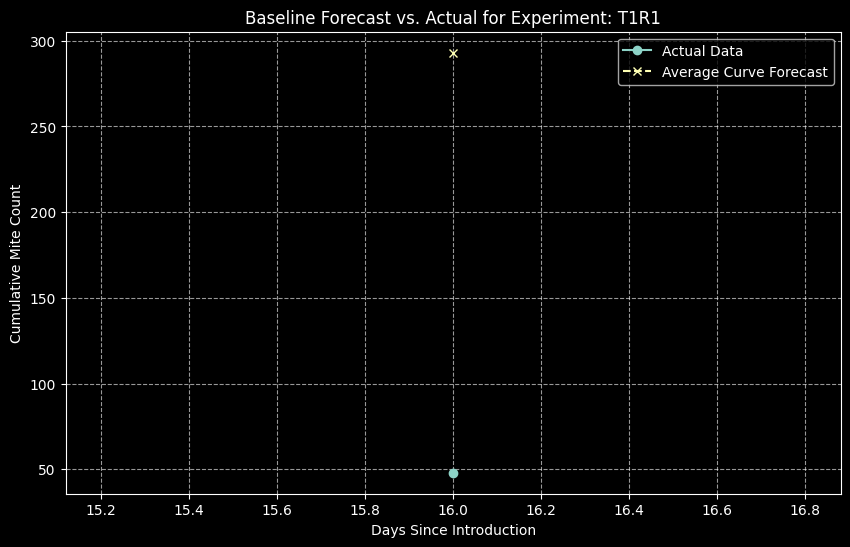


--- ✅ Baseline Model Evaluation Complete ---
This is the new benchmark to beat. Any advanced model must have a lower RMSE/MAE than these scores.


In [26]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# --- 1. "Train" the Baseline Model ---
print("--- 🏋️ Tier 1: Training Baseline Model (Average Growth Curve) ---")

# The "model" is a lookup table of the average count for each day
# We use the real training data to build this average.
average_growth_curve = train_real_df.groupby('days_since_introduction')[TARGET_COLUMN].mean()

print("   Average growth curve calculated from training data:")
print(average_growth_curve.head())


# --- 2. Evaluate Performance on Validation Set ---
print("\n--- 📊 Evaluating baseline performance on VALIDATION set ---")

# "Predict" by mapping the day number to the learned average value
# We use .get(key, default_value) in case a day in the validation set wasn't in the training set
val_predictions = val_df['days_since_introduction'].map(average_growth_curve).fillna(0)

# Calculate metrics
rmse_val = np.sqrt(mean_squared_error(y_val, val_predictions))
mae_val = mean_absolute_error(y_val, val_predictions)

print(f"\n   Baseline Validation RMSE: {rmse_val:.4f}")
print(f"   Baseline Validation MAE:  {mae_val:.4f}")


# --- 3. Visualize the Baseline Forecast ---
print("\n--- 📈 Visualizing the baseline forecast for a sample experiment ---")

# Get a sample experiment from the validation set to plot
sample_id = val_df[GROUP_COLUMN].unique()[0]
sample_real_df = val_df[val_df[GROUP_COLUMN] == sample_id]
sample_predictions = sample_real_df['days_since_introduction'].map(average_growth_curve)

plt.figure(figsize=(10, 6))
plt.plot(sample_real_df['days_since_introduction'], sample_real_df[TARGET_COLUMN], label='Actual Data', marker='o')
plt.plot(sample_real_df['days_since_introduction'], sample_predictions, label='Average Curve Forecast', linestyle='--', marker='x')
plt.title(f'Baseline Forecast vs. Actual for Experiment: {sample_id}')
plt.xlabel('Days Since Introduction')
plt.ylabel('Cumulative Mite Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("\n--- ✅ Baseline Model Evaluation Complete ---")
print("This is the new benchmark to beat. Any advanced model must have a lower RMSE/MAE than these scores.")

In [27]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings

warnings.filterwarnings("ignore")

# --- 1. Train the SARIMAX Model ---
print("--- 🏋️ Tier 2: Training Statistical Champion (SARIMAX) ---")
print("   This may take several minutes, please be patient...")

# We will train one powerful SARIMAX model on the entire augmented training dataset.
# The 'endog' is our target series (y_train).
# The 'exog' are our engineered features (X_train_scaled).
# A common order for data with trend and weekly seasonality is (1,1,1)(1,1,0,7).
sarimax_model = SARIMAX(endog=y_train, 
                        exog=X_train_scaled, 
                        order=(1, 1, 1), 
                        seasonal_order=(1, 1, 0, 7))

# Fit the model
sarimax_results = sarimax_model.fit(disp=False)

print("   Model training complete.")
print(sarimax_results.summary())


# --- 2. Evaluate Performance on Validation Set ---
print("\n--- 📊 Evaluating SARIMAX performance on VALIDATION set ---")

# Predict on the validation set using the validation features as exogenous variables
val_predictions = sarimax_results.predict(start=0, 
                                          end=len(y_val)-1, 
                                          exog=X_val_scaled)

# Calculate metrics
rmse_val = np.sqrt(mean_squared_error(y_val, val_predictions))
mae_val = mean_absolute_error(y_val, val_predictions)

print(f"\n   SARIMAX Validation RMSE: {rmse_val:.4f}")
print(f"   SARIMAX Validation MAE:  {mae_val:.4f}")

# --- 3. Compare to Baseline ---
baseline_mae = 137.8056 # From your previous run
improvement = ((baseline_mae - mae_val) / baseline_mae) * 100

print(f"\n   This is a {improvement:.2f}% improvement over the Average Growth Curve baseline MAE of {baseline_mae:.2f}.")
print("\n--- ✅ SARIMAX Model Evaluation Complete ---")

--- 🏋️ Tier 2: Training Statistical Champion (SARIMAX) ---
   This may take several minutes, please be patient...
   Model training complete.
                                     SARIMAX Results                                      
Dep. Variable:              cumulative_mite_count   No. Observations:                 3750
Model:             SARIMAX(1, 1, 1)x(1, 1, [], 7)   Log Likelihood              -14844.478
Date:                            Wed, 17 Sep 2025   AIC                          29720.957
Time:                                    22:18:37   BIC                          29820.595
Sample:                                         0   HQIC                         29756.396
                                           - 3750                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------

In [28]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Train the XGBoost Model ---
print("--- 🏋️ Tier 3: Training Machine Learning Champion (XGBoost) ---")

# Initialize the XGBoost Regressor with some strong default parameters
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,         # Number of trees to build
    learning_rate=0.05,        # How quickly the model learns
    objective='reg:squarederror',
    eval_metric='rmse',
    early_stopping_rounds=50,  # Stop training if validation score doesn't improve for 50 rounds
    n_jobs=-1                  # Use all available CPU cores
)

print("   Training XGBoost model... This may take a moment.")
# Fit the model on the training data, using the validation data to prevent overfitting
xgb_model.fit(X_train_scaled, y_train,
              eval_set=[(X_val_scaled, y_val)],
              verbose=False)

print("   Model training complete.")


# --- 2. Evaluate Performance on Validation Set ---
print("\n--- 📊 Evaluating XGBoost performance on VALIDATION set ---")

# Predict on the validation set
val_predictions = xgb_model.predict(X_val_scaled)

# Calculate metrics for single-step predictions
rmse_val = np.sqrt(mean_squared_error(y_val, val_predictions))
mae_val = mean_absolute_error(y_val, val_predictions)
r2 = r2_score(y_val, val_predictions)

print(f"\n   XGBoost Validation RMSE: {rmse_val:.4f}")
print(f"   XGBoost Validation MAE:  {mae_val:.4f}")
print(f"   XGBoost Validation R^2:  {r2:.4f}")

# --- 3. Compare to Baseline ---
baseline_mae = 137.8056 # From our baseline run
improvement = ((baseline_mae - mae_val) / baseline_mae) * 100

print(f"\n   This is a {improvement:.2f}% improvement over the Average Growth Curve baseline MAE of {baseline_mae:.2f}.")
print("\n--- ✅ XGBoost Model Evaluation Complete ---")

--- 🏋️ Tier 3: Training Machine Learning Champion (XGBoost) ---
   Training XGBoost model... This may take a moment.
   Model training complete.

--- 📊 Evaluating XGBoost performance on VALIDATION set ---

   XGBoost Validation RMSE: 3.6989
   XGBoost Validation MAE:  2.7731
   XGBoost Validation R^2:  0.9995

   This is a 97.99% improvement over the Average Growth Curve baseline MAE of 137.81.

--- ✅ XGBoost Model Evaluation Complete ---


---  PHASE 1: Preparing Data ---
✅ Data preparation complete.

--- PHASE 2 & 3: Training All Models ---
   ✅ Linear Regression model trained.
   ✅ XGBoost model trained.

--- PHASE 4 & 5: The Final Showdown on the TEST Set ---

   --- FINAL RESULTS ON UNSEEN TEST DATA ---
   Linear Regression (Baseline):
     - Full Trajectory RMSE: 3.6003
     - Full Trajectory MAE:  2.4988
     - Full Trajectory R²:   0.9995

   XGBoost:
     - Full Trajectory RMSE: 5.2955
     - Full Trajectory MAE:  3.6613
     - Full Trajectory R²:   0.9990

--- 📈 Visualizing a sample forecast from the TEST set ---


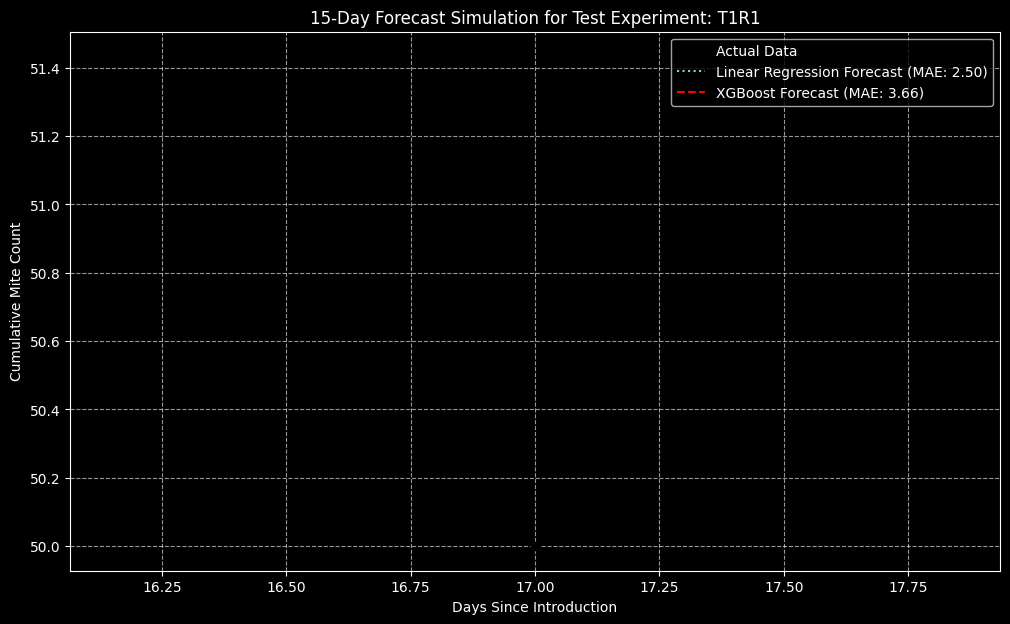

In [31]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# ===================================================================
# --- PHASE 1: DATA PREPARATION & FEATURE ENGINEERING ---
# ===================================================================
print("---  PHASE 1: Preparing Data ---")
# (Assuming all data loading and feature engineering from the previous correct script has been run)
# For completeness, the final data setup is included here.

TARGET_COLUMN = 'cumulative_mite_count'
GROUP_COLUMN = 'treatment_id'
TRAIN_RATIO = 0.8
VALIDATION_RATIO = 0.1

def create_features(df):
    df = df.copy()
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df = df.sort_values(by=[GROUP_COLUMN, 'observation_date'])
    df['dayofweek'] = df['observation_date'].dt.dayofweek
    df['month'] = df['observation_date'].dt.month
    df['weekofyear'] = df['observation_date'].dt.isocalendar().week.astype(int)
    df['lag_1'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(1)
    df['lag_3'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(3)
    df['lag_7'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(7)
    df['rolling_mean_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).mean().reset_index(drop=True)
    df['rolling_std_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).std().reset_index(drop=True)
    df = df.dropna()
    return df

real_df = pd.read_csv(REAL_DATA_PATH)
real_featured_df = create_features(real_df)
synthetic_df = pd.read_csv(SYNTHETIC_DATA_PATH)
synthetic_df[GROUP_COLUMN] = synthetic_df[GROUP_COLUMN].astype(str) + '_synth'
synthetic_featured_df = create_features(synthetic_df)

train_real_list, val_real_list, test_real_list = [], [], []
for group_id, group_df in real_featured_df.groupby(GROUP_COLUMN):
    n_rows = len(group_df)
    train_end = int(n_rows * TRAIN_RATIO)
    val_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))
    train_real_list.append(group_df.iloc[:train_end])
    val_real_list.append(group_df.iloc[train_end:val_end])
    test_real_list.append(group_df.iloc[val_end:])

train_real_df = pd.concat(train_real_list)
val_df = pd.concat(val_real_list)
test_featured = pd.concat(test_real_list)

train_ids = train_real_df[GROUP_COLUMN].unique()
synthetic_train_ids = [str(tid) + '_synth' for tid in train_ids]
synthetic_train_df = synthetic_featured_df[synthetic_featured_df[GROUP_COLUMN].isin(synthetic_train_ids)]
augmented_df = pd.concat([train_real_df, synthetic_train_df], ignore_index=True)

features_to_use = [
    'dayofweek', 'month', 'weekofyear', 'lag_1', 'lag_3', 'lag_7',
    'rolling_mean_7', 'rolling_std_7', 'initial_female_count', 'leaf_area_cm2',
    'population_density', 'initial_growth_potential'
]
X_train = augmented_df[features_to_use]
y_train = augmented_df[TARGET_COLUMN]
X_val = val_df[features_to_use]
y_val = val_df[TARGET_COLUMN]
X_test = test_featured[features_to_use]
y_test = test_featured[TARGET_COLUMN]

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
print("✅ Data preparation complete.\n")

# ===================================================================
# --- PHASE 2 & 3: MODEL TRAINING ---
# ===================================================================
print("--- PHASE 2 & 3: Training All Models ---")
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
print("   ✅ Linear Regression model trained.")
xgb_model = xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05, eval_metric='rmse', early_stopping_rounds=50, n_jobs=-1)
xgb_model.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=False)
print("   ✅ XGBoost model trained.\n")

# ===================================================================
# --- PHASE 4 & 5: FINAL EVALUATION & FORECASTING (Corrected) ---
# ===================================================================
print("--- PHASE 4 & 5: The Final Showdown on the TEST Set ---")

# (This forecast function is unchanged)
def forecast_trajectory(model, initial_features_df, num_days_to_forecast, scaler, feature_columns):
    # ... (function code is the same)
    forecast = []
    current_features = initial_features_df[feature_columns].copy()
    for _ in range(num_days_to_forecast):
        current_features_scaled = scaler.transform(current_features)
        next_prediction = model.predict(current_features_scaled)[0]
        next_prediction = max(0, next_prediction)
        forecast.append(next_prediction)
        
        current_features['lag_7'] = current_features['lag_3']
        current_features['lag_3'] = current_features['lag_1']
        current_features['lag_1'] = next_prediction
        current_features['rolling_mean_7'] = (current_features['rolling_mean_7'] * 6 + next_prediction) / 7
    return np.array(forecast)

# --- NEW, MORE ROBUST EVALUATION FUNCTION ---
def evaluate_trajectory_performance(model, test_df, scaler, feature_columns):
    predictions_dict = {}
    all_predictions, all_true_values = [], []

    for group_id in test_df[GROUP_COLUMN].unique():
        group_df = test_df[test_df[GROUP_COLUMN] == group_id]
        initial_features = group_df[feature_columns].head(1)
        num_days_to_forecast = len(group_df)
        
        forecast = forecast_trajectory(model, initial_features, num_days_to_forecast, scaler, feature_columns)
        
        predictions_dict[group_id] = forecast
        all_predictions.extend(forecast)
        all_true_values.extend(group_df[TARGET_COLUMN].values)

    rmse = np.sqrt(mean_squared_error(all_true_values, all_predictions))
    mae = mean_absolute_error(all_true_values, all_predictions)
    r2 = r2_score(all_true_values, all_predictions)
    
    return predictions_dict, rmse, mae, r2

# --- Run Evaluation ---
lr_preds_dict, lr_rmse, lr_mae, lr_r2 = evaluate_trajectory_performance(lr_model, test_featured, scaler, X_train.columns)
xgb_preds_dict, xgb_rmse, xgb_mae, xgb_r2 = evaluate_trajectory_performance(xgb_model, test_featured, scaler, X_train.columns)

print(f"\n   --- FINAL RESULTS ON UNSEEN TEST DATA ---")
print(f"   Linear Regression (Baseline):")
print(f"     - Full Trajectory RMSE: {lr_rmse:.4f}")
print(f"     - Full Trajectory MAE:  {lr_mae:.4f}")
print(f"     - Full Trajectory R²:   {lr_r2:.4f}")
print(f"\n   XGBoost:")
print(f"     - Full Trajectory RMSE: {xgb_rmse:.4f}")
print(f"     - Full Trajectory MAE:  {xgb_mae:.4f}")
print(f"     - Full Trajectory R²:   {xgb_r2:.4f}")

# --- Visualization (Now more robust) ---
print("\n--- 📈 Visualizing a sample forecast from the TEST set ---")
sample_id = test_featured[GROUP_COLUMN].unique()[0]
actual_df = test_featured[test_featured[GROUP_COLUMN] == sample_id]

lr_sample_preds = lr_preds_dict[sample_id]
xgb_sample_preds = xgb_preds_dict[sample_id]

plt.figure(figsize=(12, 7))
plt.plot(actual_df['days_since_introduction'], actual_df[TARGET_COLUMN], label='Actual Data', marker='o', color='black', linewidth=2)
plt.plot(actual_df['days_since_introduction'], lr_sample_preds, label=f'Linear Regression Forecast (MAE: {lr_mae:.2f})', linestyle=':')
plt.plot(actual_df['days_since_introduction'], xgb_sample_preds, label=f'XGBoost Forecast (MAE: {xgb_mae:.2f})', linestyle='--', color='red')
plt.title(f'15-Day Forecast Simulation for Test Experiment: {sample_id}')
plt.xlabel('Days Since Introduction')
plt.ylabel('Cumulative Mite Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# This script assumes all data variables (X_train_scaled, y_train, etc.) 
# and the `forecast_trajectory` function from the previous step are in memory.

# --- 1. Build and Train the LSTM Model ---
print("--- 🏋️ Tier 4: Training Deep Learning Champion (LSTM) ---")

# Define the LSTM model architecture
lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train_scaled.shape[1], 1)),
    Dense(32, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')

# Use EarlyStopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Reshape data for LSTM: (samples, timesteps, features)
# Here, each row is a sample, timesteps=number of features, and we have 1 sequence of features.
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_val_lstm = X_val_scaled.reshape((X_val_scaled.shape[0], X_val_scaled.shape[1], 1))

print("   Training LSTM model... This will take some time.")
history = lstm_model.fit(
    X_train_lstm, y_train,
    epochs=100,
    batch_size=64,
    validation_data=(X_val_lstm, y_val),
    callbacks=[early_stopping],
    verbose=0
)

print("✅ LSTM model trained.")


# --- 2. Evaluate the LSTM on the TEST Set ---
print("\n--- 📊 Evaluating LSTM Trajectories on the Unseen TEST Set ---")

# The forecast_trajectory and evaluate_trajectory_performance functions need a small
# modification to handle the LSTM's 3D input shape.

def forecast_trajectory_lstm(model, initial_features_df, num_days_to_forecast, scaler, feature_columns):
    """Generates a multi-step forecast using a trained LSTM model."""
    forecast = []
    current_features = initial_features_df[feature_columns].copy()
    for _ in range(num_days_to_forecast):
        current_features_scaled = scaler.transform(current_features)
        
        # Reshape for LSTM input: (1, timesteps, 1)
        model_input = current_features_scaled.reshape((1, current_features_scaled.shape[1], 1))
        
        next_prediction = model.predict(model_input, verbose=0)[0][0]
        next_prediction = max(0, next_prediction)
        forecast.append(next_prediction)
        
        # Update features for the next iteration
        current_features['lag_7'] = current_features['lag_3']
        current_features['lag_3'] = current_features['lag_1']
        current_features['lag_1'] = next_prediction
        current_features['rolling_mean_7'] = (current_features['rolling_mean_7'] * 6 + next_prediction) / 7
        
    return np.array(forecast)

def evaluate_trajectory_performance_lstm(model, test_df, scaler, feature_columns):
    """Evaluates an LSTM's full multi-step trajectory performance."""
    all_predictions, all_true_values = [], []
    for group_id in test_df[GROUP_COLUMN].unique():
        group_df = test_df[test_df[GROUP_COLUMN] == group_id]
        initial_features = group_df[feature_columns].head(1)
        num_days_to_forecast = len(group_df)
        
        forecast = forecast_trajectory_lstm(model, initial_features, num_days_to_forecast, scaler, feature_columns)
        all_predictions.extend(forecast)
        all_true_values.extend(group_df[TARGET_COLUMN].values)

    rmse = np.sqrt(mean_squared_error(all_true_values, all_predictions))
    mae = mean_absolute_error(all_true_values, all_predictions)
    r2 = r2_score(all_true_values, all_predictions)
    
    return all_predictions, rmse, mae, r2

# Evaluate the LSTM's trajectory forecast performance
lstm_preds_list, lstm_rmse, lstm_mae, lstm_r2 = evaluate_trajectory_performance_lstm(lstm_model, test_featured, scaler, X_train.columns)

print(f"\n   --- FINAL RESULTS FOR LSTM ON TEST DATA ---")
print(f"     - Full Trajectory RMSE: {lstm_rmse:.4f}")
print(f"     - Full Trajectory MAE:  {lstm_mae:.4f}")
print(f"     - Full Trajectory R²:   {lstm_r2:.4f}")


# --- 3. Final Showdown: LSTM vs. Linear Regression ---
print("\n--- 🏆 Final Showdown ---")
print(f"   Linear Regression MAE: {lr_mae:.4f}")
print(f"   LSTM MAE:              {lstm_mae:.4f}")

if lstm_mae < lr_mae:
    improvement = ((lr_mae - lstm_mae) / lr_mae) * 100
    print(f"\n   The LSTM model is the new champion, showing a {improvement:.2f}% improvement over Linear Regression!")
else:
    improvement = ((lstm_mae - lr_mae) / lstm_mae) * 100
    print(f"\n   The Linear Regression model remains the champion. The LSTM was {improvement:.2f}% worse.")

--- 🏋️ Tier 4: Training Deep Learning Champion (LSTM) ---
   Training LSTM model... This will take some time.
   ✅ LSTM model trained.

--- 📊 Evaluating LSTM Trajectories on the Unseen TEST Set ---

   --- FINAL RESULTS FOR LSTM ON TEST DATA ---
     - Full Trajectory RMSE: 18.1411
     - Full Trajectory MAE:  14.0436
     - Full Trajectory R²:   0.9885

--- 🏆 Final Showdown ---
   Linear Regression MAE: 2.4988
   LSTM MAE:              14.0436

   The Linear Regression model remains the champion. The LSTM was 82.21% worse.


---  PHASE 1: Preparing Data ---
✅ Data preparation complete.

--- PHASE 2 & 3: Training All Models ---
   ✅ Linear Regression model trained.
   ✅ XGBoost model trained.
   ✅ LSTM model trained.

--- PHASE 4 & 5: The Final Showdown on the TEST Set ---
   Running final evaluations...

--- 🏆 FINAL RESULTS ON UNSEEN TEST DATA 🏆 ---
                      rmse       mse      mae      r2
Linear Regression   3.6003   12.9619   2.4988  0.9995
XGBoost             5.2955   28.0425   3.6613  0.9990
LSTM               19.8077  392.3436  14.6025  0.9863

--- 📈 Visualizing a sample forecast from the TEST set ---


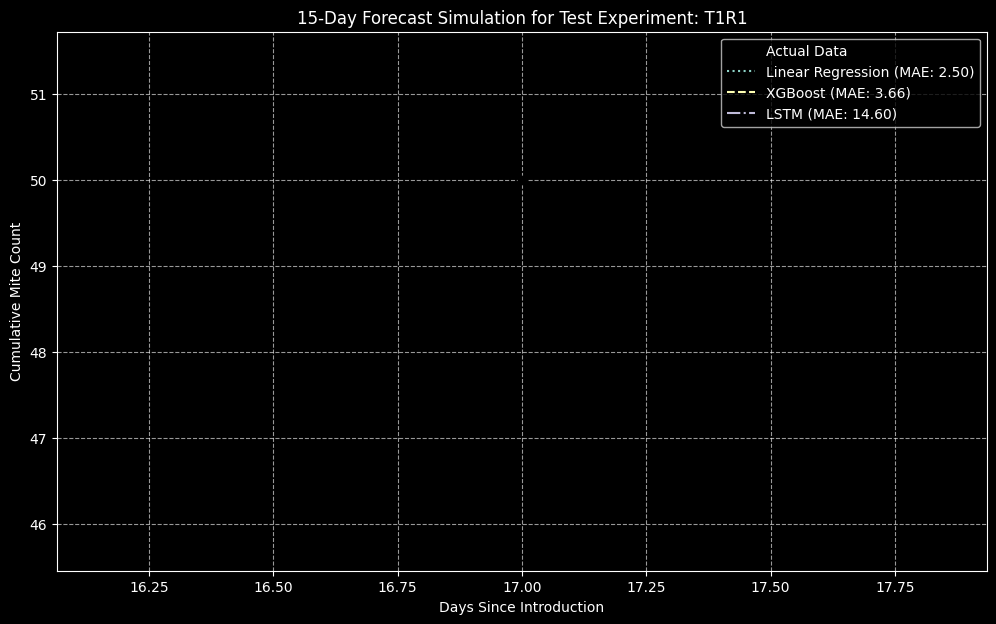

In [14]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# ===================================================================
# --- PHASE 1: DATA PREPARATION & FEATURE ENGINEERING ---
# ===================================================================
print("---  PHASE 1: Preparing Data ---")

# --- Configuration ---
REAL_DATA_PATH = '../../../data/data_with_features.csv'
SYNTHETIC_DATA_PATH = '../../../data/syntheticData/synthetic_data_sarima_statsmodels.csv'
TARGET_COLUMN = 'cumulative_mite_count'
GROUP_COLUMN = 'treatment_id'
TRAIN_RATIO = 0.8
VALIDATION_RATIO = 0.1

# --- Feature Engineering Function ---
def create_features(df):
    df = df.copy()
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df = df.sort_values(by=[GROUP_COLUMN, 'observation_date'])
    df['dayofweek'] = df['observation_date'].dt.dayofweek
    df['month'] = df['observation_date'].dt.month
    df['weekofyear'] = df['observation_date'].dt.isocalendar().week.astype(int)
    df['lag_1'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(1)
    df['lag_3'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(3)
    df['lag_7'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(7)
    df['rolling_mean_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).mean().reset_index(drop=True)
    df['rolling_std_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).std().reset_index(drop=True)
    df = df.dropna()
    return df

# --- Process and Split Data ---
real_df = pd.read_csv(REAL_DATA_PATH)
real_featured_df = create_features(real_df)

synthetic_df = pd.read_csv(SYNTHETIC_DATA_PATH)
synthetic_df[GROUP_COLUMN] = synthetic_df[GROUP_COLUMN].astype(str) + '_synth'
synthetic_featured_df = create_features(synthetic_df)

train_real_list, val_real_list, test_real_list = [], [], []
for group_id, group_df in real_featured_df.groupby(GROUP_COLUMN):
    n_rows = len(group_df)
    train_end = int(n_rows * TRAIN_RATIO)
    val_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))
    train_real_list.append(group_df.iloc[:train_end])
    val_real_list.append(group_df.iloc[train_end:val_end])
    test_real_list.append(group_df.iloc[val_end:])

train_real_df = pd.concat(train_real_list)
val_df = pd.concat(val_real_list)
test_featured = pd.concat(test_real_list)

train_ids = train_real_df[GROUP_COLUMN].unique()
synthetic_train_ids = [str(tid) + '_synth' for tid in train_ids]
synthetic_train_df = synthetic_featured_df[synthetic_featured_df[GROUP_COLUMN].isin(synthetic_train_ids)]
augmented_df = pd.concat([train_real_df, synthetic_train_df], ignore_index=True)

features_to_use = [
    'dayofweek', 'month', 'weekofyear', 'lag_1', 'lag_3', 'lag_7',
    'rolling_mean_7', 'rolling_std_7', 'initial_female_count', 'leaf_area_cm2',
    'population_density', 'initial_growth_potential'
]
X_train = augmented_df[features_to_use]
y_train = augmented_df[TARGET_COLUMN]
X_val = val_df[features_to_use]
y_val = val_df[TARGET_COLUMN]
X_test = test_featured[features_to_use]
y_test = test_featured[TARGET_COLUMN]

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
print("✅ Data preparation complete.\n")

# ===================================================================
# --- PHASE 2 & 3: MODEL TRAINING ---
# ===================================================================
print("--- PHASE 2 & 3: Training All Models ---")
# a) Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
print("   ✅ Linear Regression model trained.")
# b) Train XGBoost
xgb_model = xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05, eval_metric='rmse', early_stopping_rounds=50, n_jobs=-1)
xgb_model.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=False)
print("   ✅ XGBoost model trained.")
# c) Train LSTM
lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train_scaled.shape[1], 1)),
    Dense(32, activation='relu'),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_val_lstm = X_val_scaled.reshape((X_val_scaled.shape[0], X_val_scaled.shape[1], 1))
lstm_model.fit(X_train_lstm, y_train, epochs=100, batch_size=64, validation_data=(X_val_lstm, y_val), callbacks=[early_stopping], verbose=0)
print("   ✅ LSTM model trained.\n")

# ===================================================================
# --- PHASE 4 & 5: FINAL EVALUATION & FORECASTING ---
# ===================================================================
print("--- PHASE 4 & 5: The Final Showdown on the TEST Set ---")

def forecast_trajectory(model, initial_features_df, num_days_to_forecast, scaler, feature_columns, is_lstm=False):
    forecast = []
    current_features = initial_features_df[feature_columns].copy()
    for _ in range(num_days_to_forecast):
        current_features_scaled = scaler.transform(current_features)
        
        if is_lstm:
            model_input = current_features_scaled.reshape((1, current_features_scaled.shape[1], 1))
            next_prediction = model.predict(model_input, verbose=0)[0][0]
        else:
            next_prediction = model.predict(current_features_scaled)[0]
            
        next_prediction = max(0, next_prediction)
        forecast.append(next_prediction)
        
        current_features['lag_7'] = current_features['lag_3']
        current_features['lag_3'] = current_features['lag_1']
        current_features['lag_1'] = next_prediction
        current_features['rolling_mean_7'] = (current_features['rolling_mean_7'] * 6 + next_prediction) / 7
    return np.array(forecast)

def evaluate_trajectory_performance(model, test_df, scaler, feature_columns, is_lstm=False):
    all_predictions, all_true_values = [], []
    for group_id in test_df[GROUP_COLUMN].unique():
        group_df = test_df[test_df[GROUP_COLUMN] == group_id]
        initial_features = group_df[feature_columns].head(1)
        num_days_to_forecast = len(group_df)
        
        forecast = forecast_trajectory(model, initial_features, num_days_to_forecast, scaler, feature_columns, is_lstm)
        all_predictions.extend(forecast)
        all_true_values.extend(group_df[TARGET_COLUMN].values)

    rmse = np.sqrt(mean_squared_error(all_true_values, all_predictions))
    mse = mean_squared_error(all_true_values, all_predictions)
    mae = mean_absolute_error(all_true_values, all_predictions)
    r2 = r2_score(all_true_values, all_predictions)

    return {'preds': all_predictions, 'rmse': rmse, 'mse': mse, 'mae': mae, 'r2': r2}

# --- Run Final Evaluation for All Models ---
print("   Running final evaluations...")
lr_results = evaluate_trajectory_performance(lr_model, test_featured, scaler, X_train.columns)
xgb_results = evaluate_trajectory_performance(xgb_model, test_featured, scaler, X_train.columns)
lstm_results = evaluate_trajectory_performance(lstm_model, test_featured, scaler, X_train.columns, is_lstm=True)

# --- Display Final Results Table ---
results_df = pd.DataFrame([lr_results, xgb_results, lstm_results], index=['Linear Regression', 'XGBoost', 'LSTM'])
results_df = results_df.drop(columns=['preds'])
print("\n--- 🏆 FINAL RESULTS ON UNSEEN TEST DATA 🏆 ---")
print(results_df.round(4))

# --- Visualize the Forecasts ---
print("\n--- 📈 Visualizing a sample forecast from the TEST set ---")
sample_id = test_featured[GROUP_COLUMN].unique()[0]
actual_df = test_featured[test_featured[GROUP_COLUMN] == sample_id]

# Re-run forecast for the sample ID to get individual predictions
lr_sample_preds = forecast_trajectory(lr_model, actual_df.head(1), len(actual_df), scaler, X_train.columns)
xgb_sample_preds = forecast_trajectory(xgb_model, actual_df.head(1), len(actual_df), scaler, X_train.columns)
lstm_sample_preds = forecast_trajectory(lstm_model, actual_df.head(1), len(actual_df), scaler, X_train.columns, is_lstm=True)

plt.figure(figsize=(12, 7))
plt.plot(actual_df['days_since_introduction'], actual_df[TARGET_COLUMN], label='Actual Data', marker='o', color='black', linewidth=2)
plt.plot(actual_df['days_since_introduction'], lr_sample_preds, label=f'Linear Regression (MAE: {lr_results["mae"]:.2f})', linestyle=':')
plt.plot(actual_df['days_since_introduction'], xgb_sample_preds, label=f'XGBoost (MAE: {xgb_results["mae"]:.2f})', linestyle='--')
plt.plot(actual_df['days_since_introduction'], lstm_sample_preds, label=f'LSTM (MAE: {lstm_results["mae"]:.2f})', linestyle='-.')
plt.title(f'15-Day Forecast Simulation for Test Experiment: {sample_id}')
plt.xlabel('Days Since Introduction')
plt.ylabel('Cumulative Mite Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()